In [27]:
# pip install osmnx


In [28]:
# pip install networkx

In [29]:
# pip install --no-cache-dir --force-reinstall pyproj

In [30]:
# pip install --upgrade --force-reinstall "numpy<2" scipy osmnx networkx

In [31]:
pip install folium

DEPRECATION: Loading egg at /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/ChemDataExtractor-1.3.0-py3.12.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [32]:
import numpy as np
import osmnx as ox
import networkx as nx
import folium

# print("NumPy:", np.__version__)
# print("OSMnx:", ox.__version__)

In [33]:
import os

# Evita que una instalación externa de Conda/PROJ interfiera
os.environ.pop("PROJ_LIB", None)
os.environ.pop("PROJ_DATA", None)

import pyproj

# Fuerza a pyproj a usar su propia carpeta de datos
pyproj.datadir.set_data_dir(pyproj.datadir.get_data_dir())

print("PROJ usa:", pyproj.datadir.get_data_dir())

PROJ usa: /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pyproj/proj_dir/share/proj


In [34]:
import osmnx as ox

G = ox.graph_from_place(
    "Morelia, Michoacán, México",
    network_type="drive"
)

In [35]:
origen = (19.7008, -101.1844)
destino = (19.6800, -101.2060)

In [36]:
nodo_origen = ox.distance.nearest_nodes(
    G, 
    origen[1], 
    origen[0])

nodo_destino = ox.distance.nearest_nodes(
    G, 
    destino[1], 
    destino[0])

In [37]:
ruta = nx.shortest_path(
    G,
    source=nodo_origen,
    target=nodo_destino,
    weight="length")

In [38]:
# Convierte la ruta calculada a geometría real de calles
ruta_gdf = ox.routing.route_to_gdf(G, ruta)

In [39]:
# Mapa base de Morelia
mapa = folium.Map(
    location=[19.7008, -101.1844],
    zoom_start=13,
    tiles="OpenStreetMap"
    )

In [40]:
# Ruta en rojo
folium.GeoJson(
    ruta_gdf.__geo_interface__,
    style_function=lambda _: {
        "color": "red",
        "weight": 5,
        "opacity": 0.9
    }
).add_to(mapa)

In [41]:
# Marcadores de salida y llegada
folium.Marker(
    origen,
    tooltip="Origen",
    icon=folium.Icon(color="green")
).add_to(mapa)

folium.Marker(
    destino,
    tooltip="Destino",
    icon=folium.Icon(color="red")
).add_to(mapa)

In [42]:
from pathlib import Path
import webbrowser

archivo = Path("ruta_morelia.html").resolve()
mapa.save(archivo)

webbrowser.open(archivo.as_uri())
print(f"Mapa abierto en el navegador: {archivo}")

Mapa abierto en el navegador: /Users/carlosabraham1/Desktop/geolocalizacion/ruta_morelia.html


In [43]:
distancia_m = nx.path_weight(G, ruta, weight="length")
print(f"Distancia de la ruta: {distancia_m:.2f} metros")

Distancia de la ruta: 4206.59 metros


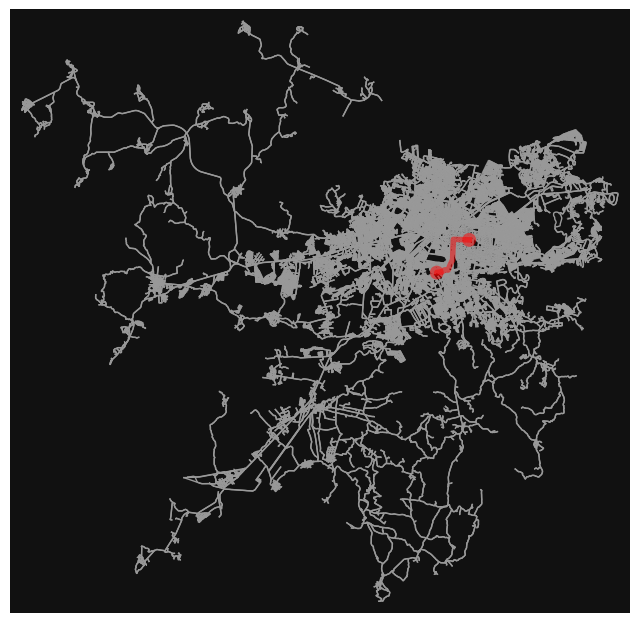

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [44]:
# Mostrar la ruta
ox.plot_graph_route(
    G,
    ruta,
    route_color="red",
    route_linewidth=4,
    node_size=0
)